In [84]:
import osmnx as ox
import networkx as nx
import r5py as r

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import h3

pd.set_option("display.max_columns", None)

In [ ]:
fp = "chile-latest.osm.pbf"
place_name = "Provincia de Concepción, Chile"
place_string = "_".join(place_name.lower().split(",")[0].split(" "))

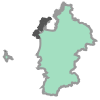

In [ ]:
area_gdf = ox.geocode_to_gdf(place_name)
area = area_gdf.geometry.iloc[0]
area

In [ ]:
# load blocks from census
# i will use this after to assign n_per value to each origin point

blocks_gdf = gpd.read_parquet("blocks/Cartografia_censo2024_Pais_Manzanas.parquet")
blocks_gdf = blocks_gdf[blocks_gdf.PROVINCIA == "CONCEPCIÓN"]
blocks_gdf = blocks_gdf[blocks_gdf.n_per > 0]
blocks_gdf

,OBJECTID,CUT,COD_REGION,REGION,COD_PROVINCIA,PROVINCIA,COMUNA,AREA_C,MANZENT,DISTRITO,COD_DISTRITO,COD_LOCALIDAD,COD_ZONA,LOCALIDAD,COD_ENTIDAD,COD_MANZANA,ENTIDAD,TIPO_MZ,COD_CATEGORIA,CATEGORIA,MZ_BASE_CENSO,ID_ENTIDAD,ID_LOCALIDAD,ID_DISTRITO,ID_ZONA,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas,prom_edad,n_inmigrantes,n_nacionalidad,n_pueblos_orig,n_afrodescendencia,n_lengua_indigena,n_religion,n_dificultad_ver,n_dificultad_oir,n_dificultad_mover,n_dificultad_cogni,n_dificultad_cuidado,n_dificultad_comunic,n_discapacidad,n_estcivcon_casado,n_estcivcon_conviviente,n_estcivcon_conv_civil,n_estcivcon_anul_sep_div,n_estcivcon_viudo,n_estcivcon_soltero,prom_escolaridad18,n_asistencia_parv,n_asistencia_basica,n_asistencia_media,n_asistencia_superior,n_cine_nunca_curso_primera_infancia,n_cine_primaria,n_cine_secundaria,n_cine_terciaria_maestria_doctorado,n_cine_especial_diferencial,n_analfabet,n_ocupado,n_desocupado,n_fuera_fuerza_trabajo,n_cise_rec_independientes,n_cise_rec_dependientes,n_cise_rec_trabajador_no_remunerado,n_ciuo_1,n_ciuo_2,n_ciuo_3,n_ciuo_4,n_ciuo_5,n_ciuo_6,n_ciuo_7,n_ciuo_8,n_ciuo_9,n_ciuo_0,n_caenes_A,n_caenes_B,n_caenes_C,n_caenes_D,n_caenes_E,n_caenes_F,n_caenes_G,n_caenes_H,n_caenes_I,n_caenes_J,n_caenes_K,n_caenes_L,n_caenes_M,n_caenes_N,n_caenes_O,n_caenes_P,n_caenes_Q,n_caenes_R,n_caenes_S,n_caenes_T,n_caenes_U,n_transporte_auto,n_transporte_publico,n_transporte_camina,n_transporte_bicicleta,n_transporte_motocicleta,n_transporte_cab_lan_bote,n_transporte_otros,n_hog,prom_per_hog,n_hog_unipersonales,n_hog_60,n_hog_menores,n_jefatura_mujer,n_tenencia_propia_pagada,n_tenencia_propia_pagandose,n_tenencia_arrendada_contrato,n_tenencia_arrendada_sin_contrato,n_tenencia_cedida_trabajo,n_tenencia_cedida_familiar,n_tenencia_otro,n_comb_cocina_gas,n_comb_cocina_parafina,n_comb_cocina_lena,n_comb_cocina_pellet,n_comb_cocina_carbon,n_comb_cocina_electricidad,n_comb_cocina_solar,n_comb_cocina_no_utiliza,n_comb_calefaccion_gas,n_comb_calefaccion_parafina,n_comb_calefaccion_lena,n_comb_calefaccion_pellet,n_comb_calefaccion_carbon,n_comb_calefaccion_electricidad,n_comb_calefaccion_otra,n_comb_calefaccion_no_utiliza,n_serv_tel_movil,n_serv_compu,n_serv_tablet,n_serv_internet_fija,n_serv_internet_movil,n_serv_internet_satelital,n_internet,n_vp,n_vp_ocupada,n_vp_desocupada,n_tipo_viv_casa,n_tipo_viv_depto,n_tipo_viv_indigena,n_tipo_viv_pieza,n_tipo_viv_mediagua,n_tipo_viv_movil,n_tipo_viv_otro,n_dormitorios_1,n_dormitorios_2,n_dormitorios_3,n_dormitorios_4,n_dormitorios_5,n_dormitorios_6_o_mas,n_viv_hacinadas,n_viv_irrecuperables,n_hog_allegados,n_nucleos_hacinados_allegados,n_viv_no_ampliables,n_deficit_cuantitativo,n_mat_paredes_hormigon,n_mat_paredes_albanileria,n_mat_paredes_tabique_forrado,n_mat_paredes_tabique_sin_forro,n_mat_paredes_artesanal,n_mat_paredes_precarios,n_mat_techo_tejas,n_mat_techo_hormigon,n_mat_techo_zinc,n_mat_techo_fibrocemento,n_mat_techo_fonolita,n_mat_techo_paja,n_mat_techo_precarios,n_mat_techo_sin_cubierta,n_mat_piso_radier_con_revestimiento,n_mat_piso_radier_sin_revestimiento,n_mat_piso_baldosa_cemento,n_mat_piso_capa_cemento,n_mat_piso_tierra,n_fuente_agua_publica,n_fuente_agua_pozo,n_fuente_agua_camion,n_fuente_agua_rio,n_distrib_agua_llave,n_distrib_agua_llave_fuera,n_distrib_agua_acarreo,n_serv_hig_alc_dentro,n_serv_hig_alc_fuera,n_serv_hig_fosa,n_serv_hig_pozo,n_serv_hig_acequia_canal,n_serv_hig_cajon_otro,n_serv_hig_bano_quimico,n_serv_hig_bano_seco,n_serv_hig_no_tiene,n_fuente_elect_publica,n_fuente_elect_diesel,n_fuente_elect_solar,n_fuente_elect_eolica,n_fuente_elect_otro,n_fuente_elect_no_tiene,n_basura_servicios,n_basura_entierra,n_basura_eriazo,n_basura_rio,n_basura_otro,SHAPE_Length,SHAPE_Area,SHAPE
14084,14085,8106,8,BIOBÍO,81,CONCEPCIÓN,LOTA,URBANO,8.106011e+12,LOTA ALTO,1,4,1,LOTA,1,3,LOTA,URBANO,1,Ciudad,1,8.106004e+11,81061004.0,810601.0,810601001.0,136.0,63.0,73.0,19.0,17.0,10.0,13.0,31.0,26.0,20.0,32.8,

In [139]:
# load points and hexagons

points_gdf = gpd.read_parquet(f"points/points_{place_string}.parquet")
hexagons_gdf = gpd.read_parquet(f"hexagons/hexagons_{place_string}.parquet")

hexagons_gdf

,cell,geometry
0,89b2dbca64bffff,"POLYGON ((-73.14735 -37.07629, -73.1466 -37.07..."
2,89b2dbca653ffff,"POLYGON ((-73.14509 -37.07174, -73.14434 -37.0..."
5,89b2dbca65bffff,"POLYGON ((-73.14785 -37.07332, -73.1471 -37.07..."
7,89b2dbcb5d7ffff,"POLYGON ((-73.15937 -37.07666, -73.15862 -37.0..."
8,89b2dbcb5d3ffff,"POLYGON ((-73.16262 -37.07528, -73.16187 -37.0..."
...,...,...
19097,89b2dbc2a5bffff,"POLYGON ((-72.96065 -37.05685, -72.9599 -37.05..."
19100,89b2dbc2a7bffff,"POLYGON ((-72.95365 -37.06258, -72.9529 -37.06..."
19101,89b2dbc2a4fffff,"POLYGON ((-72.95689 -37.0612, -72.95615 -37.05..."
19108,89b2dbc2a47ffff,"POLYGON ((-72.95415 -37.05962, -72.95341 -37.0..."


In [135]:
# leer nodes y edges desde el gpk con geopandas
nodes_gdf = gpd.read_file(f"./network/{place_string}.gpkg", layer="nodes", encoding="latin-1")
edges_gdf = gpd.read_file(f"./network/{place_string}.gpkg", layer="edges", encoding="latin-1")

# asignar 'osmid' como index para nodes_gdf, y ('u', 'v', 'key') como multi-index para edges_gdf
nodes_gdf = nodes_gdf.set_index("osmid")
edges_gdf = edges_gdf.set_index(["u", "v", "key"])

# 2. Reconstruct the graph with OSMnx
G = ox.graph_from_gdfs(nodes_gdf, edges_gdf)
# ox.plot_graph(G, figsize=(30,30), edge_linewidth=0.1, node_size=0.5, node_color="white", bgcolor="black")

(-36.9268099, -36.7644238)

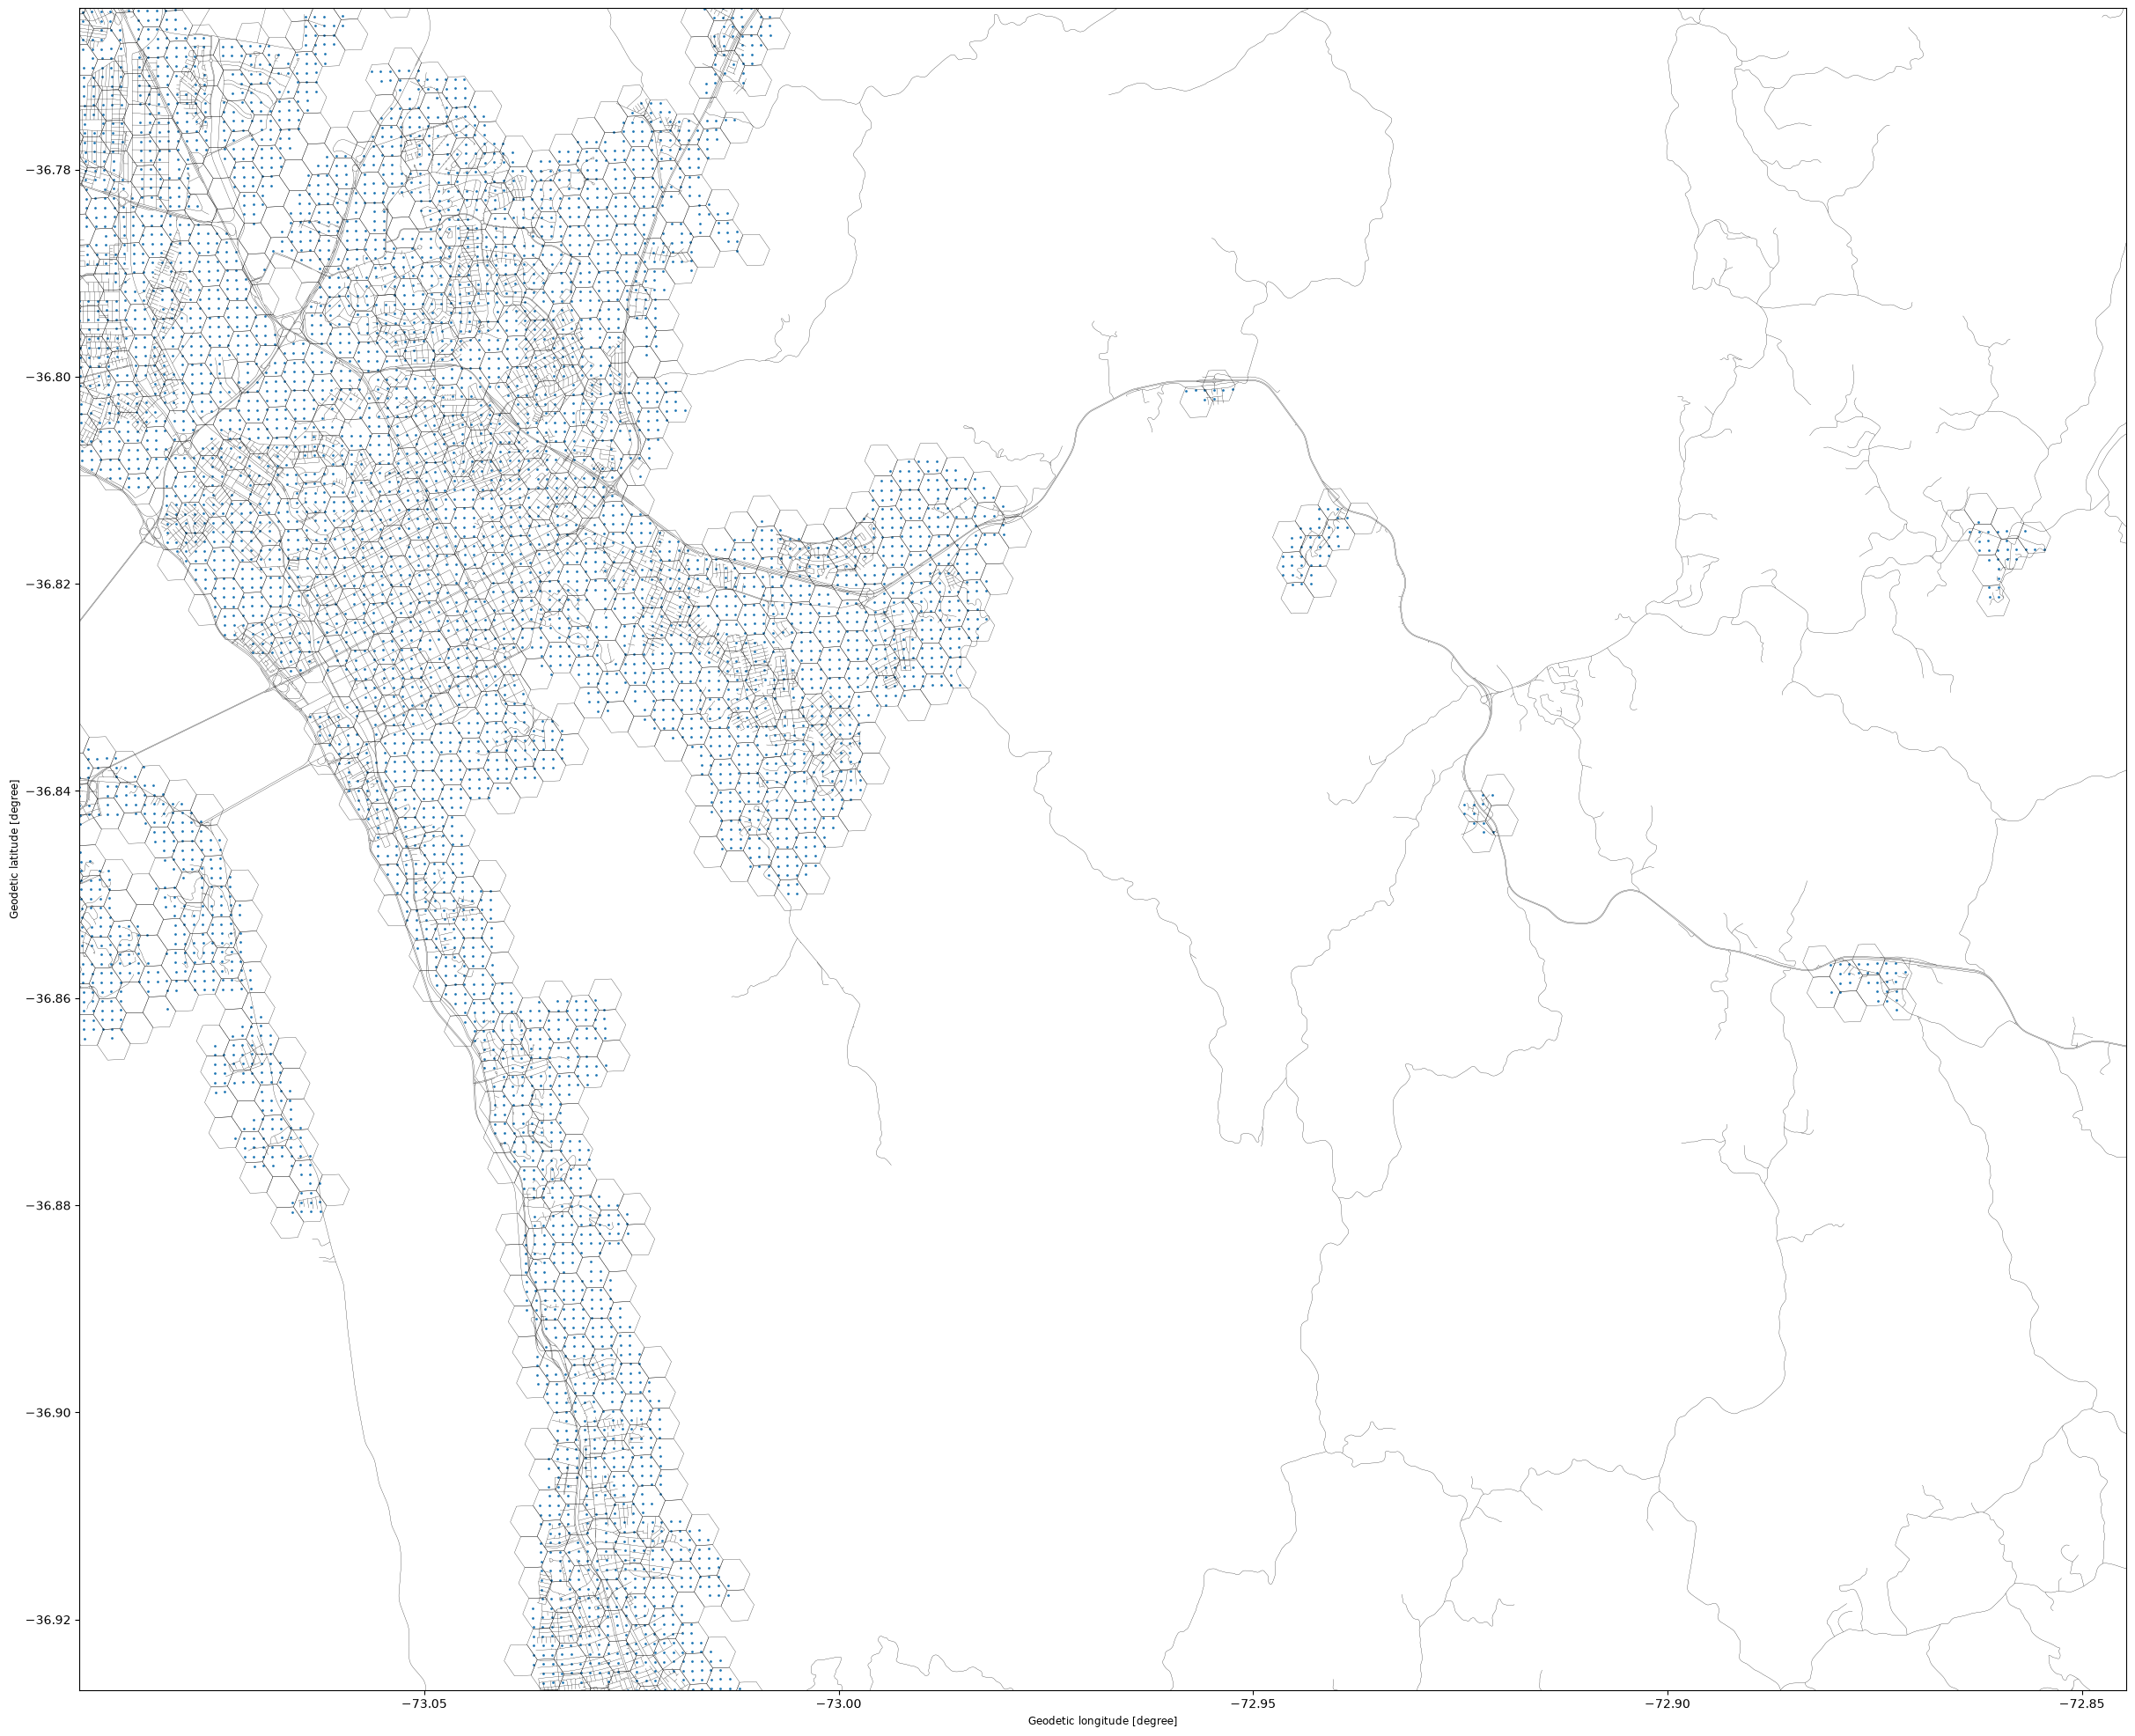

In [144]:
ax = area_gdf.plot(figsize=(30,30), color="none", linewidth=0.1)
points_gdf.plot(ax=ax, markersize=1)
edges_gdf.plot(ax=ax, linewidth=0.2, color="black")
hexagons_gdf.plot(ax=ax, linewidth=0.2, color="none")

# this is to focus and zoom to concepción
ax.set_xlim(-73.0915891, -72.8446184)
ax.set_ylim(-36.9268099, -36.7644238)

In [145]:
# load points of interest as they will be the destination

pois_gdf = gpd.read_parquet(f"pois/pois_{place_string}.parquet")
pois_gdf

,id,x,y,amenity,geometry
0,310587688,-73.102165,-36.784689,waste_disposal,POINT (-73.10216 -36.78469)
1,323548006,-72.957228,-36.620878,fuel,POINT (-72.95723 -36.62088)
2,324660871,-72.918909,-36.747044,fuel,POINT (-72.91891 -36.74704)
3,325201200,-72.934366,-36.529894,parking,POINT (-72.93437 -36.52989)
4,325210967,-72.935317,-36.530670,parking,POINT (-72.93532 -36.53067)
...,...,...,...,...,...
4934,10616261,-73.048426,-36.777372,fountain,POINT (-73.04843 -36.77737)
4935,10650253,-73.056031,-36.817421,parking,POINT (-73.05603 -36.81742)
4936,11175733,-72.937338,-36.972434,parking,POINT (-72.93734 -36.97243)
4937,18996230,-73.103502,-36.796851,social_facility,POINT (-73.1035 -36.79685)
